# Clasificación lineal y algoritmo del perceptrón

En esta sección se estudia el funcionamiento de un clasificador lineal y del algoritmo del perceptrón. En primer lugar, se utilizan los parámetros $w$ (vector de pesos) y $b$ (sesgo) para construir la función de decisión $f(x) = w^T x + b$, la cual permite determinar la clase a la que pertenece una observación. A partir de esta función, se obtiene la frontera de decisión (que corresponde a la recta donde $w^T x + b = 0$) y se clasifican varios puntos de prueba según el signo del resultado.

Para realizar los cálculos vectoriales y el producto punto de forma eficiente se utiliza la biblioteca **NumPy**. Asimismo, se emplea **Matplotlib** para representar gráficamente la frontera de decisión y observar la distribución de los puntos respecto a las clases.

Finalmente, se analiza la regla de actualización del perceptrón, la cual modifica los pesos y el sesgo cuando una observación está mal clasificada. Se presenta un ejemplo numérico para comprobar cómo se incrementa el margen de clasificación después de actualizar los parámetros con una tasa de aprendizaje $\eta$.

Punto: [0 0], score: -3, clase: -1
Punto: [1 0], score: -2, clase: -1
Punto: [2 1], score: 1, clase: 1
Punto: [3 1], score: 2, clase: 1


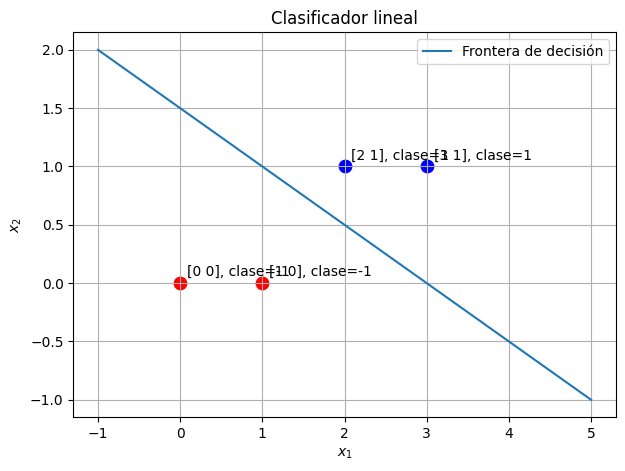

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
w = np.array([1, 2])
b = -3

def clasificar(x):
    score = np.dot(w, x) + b
    return 1 if score > 0 else -1

# Puntos de prueba
puntos = [
    np.array([0, 0]),
    np.array([1, 0]),
    np.array([2, 1]),
    np.array([3, 1])
]

for x in puntos:
    score = np.dot(w, x) + b
    prediccion = clasificar(x)
    print(f"Punto: {x}, score: {score}, clase: {prediccion}")

x1 = np.linspace(-1, 5, 200)
x2 = (3 - x1) / 2

plt.figure(figsize=(7, 5))
plt.plot(x1, x2, label="Frontera de decisión")

for x in puntos:
    clase = clasificar(x)
    color = "blue" if clase == 1 else "red"
    plt.scatter(x[0], x[1], color=color, s=80)
    plt.annotate(
        f"{x}, clase={clase}",
        (x[0], x[1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Clasificador lineal")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
def actualizar_perceptron(w, b, x, y, eta):
    score = np.dot(w, x) + b
    prediccion = 1 if score > 0 else -1

    print("Pesos iniciales:", w)
    print("Sesgo inicial:", b)
    print("Score inicial:", score)
    print("Predicción inicial:", prediccion)

    if prediccion != y:
        w_nuevo = w + eta * y * x
        b_nuevo = b + eta * y
    else:
        w_nuevo = w.copy()
        b_nuevo = b

    print("Pesos actualizados:", w_nuevo)
    print("Sesgo actualizado:", b_nuevo)

    return w_nuevo, b_nuevo


# Ejemplo del taller
w_inicial = np.array([0.0, 0.0])
b_inicial = 0.0
x = np.array([2.0, 1.0])
y = 1
eta = 0.5

w_nuevo, b_nuevo = actualizar_perceptron(
    w_inicial, b_inicial, x, y, eta
)

margen = np.dot(w_nuevo, x) * y + b_nuevo * y
print("Margen después de actualizar:", margen)

Pesos iniciales: [0. 0.]
Sesgo inicial: 0.0
Score inicial: 0.0
Predicción inicial: -1
Pesos actualizados: [1.  0.5]
Sesgo actualizado: 0.5
Margen después de actualizar: 3.0


# Clasificación por k-NN (k-Nearest Neighbors)

En esta sección se analiza el algoritmo de los $k$ vecinos más cercanos ($k$-NN), un método de aprendizaje supervisado que clasifica una nueva observación basándose en la clase mayoritaria de sus vecinos más cercanos.

El análisis se desarrolla en dos partes:
1. **Implementación manual:** Se calcula de forma explícita la distancia euclidiana entre un punto de consulta $q$ y los datos de entrenamiento utilizando **NumPy**, ordenando los vecinos y determinando la clase predicha para distintos valores de $k$ ($1$, $3$ y $5$).
2. **Uso de Scikit-Learn:** Se emplea la clase `KNeighborsClassifier` para evaluar el comportamiento del modelo sobre un conjunto de datos sintético generado mediante `make_moons`. Se utiliza `train_test_split` para evaluar el rendimiento tanto en el conjunto de entrenamiento como en el de prueba, analizando el efecto de subajuste y sobreajuste con distintos valores de $k$ ($1$, $5$ y $15$).

Finalmente, se grafican las regiones de decisión resultantes para visualizar cómo la frontera se vuelve más suave a medida que aumenta el número de vecinos $k$.

In [ ]:
import numpy as np

# Datos del taller
X = np.array([
    [0, 0],
    [1, 0],
    [3, 1],
    [0, 3],
    [1.1, 1.1]
])

y = np.array(["A", "A", "B", "B", "B"])

# Punto que queremos clasificar
q = np.array([1, 1])

# Distancias euclidianas
distancias = np.linalg.norm(X - q, axis=1)

for i, distancia in enumerate(distancias):
    print(
        f"Punto {X[i]}, clase={y[i]}, "
        f"distancia={distancia:.4f}"
    )

# Ordenar los puntos por distancia
orden = np.argsort(distancias)

print("\nVecinos ordenados:")
for i in orden:
    print(
        f"Punto: {X[i]}, clase: {y[i]}, "
        f"distancia: {distancias[i]:.4f}"
    )
from collections import Counter

def knn_manual(X, y, q, k):
    distancias = np.linalg.norm(X - q, axis=1)
    vecinos = np.argsort(distancias)[:k]
    clases = y[vecinos]

    conteo = Counter(clases)
    prediccion = conteo.most_common(1)[0][0]

    return prediccion, vecinos, clases


for k in [1, 3, 5]:
    prediccion, vecinos, clases = knn_manual(X, y, q, k)

    print(f"\nk = {k}")
    print("Clases de los vecinos:", clases)
    print("Predicción:", prediccion)

Punto [0. 0.], clase=A, distancia=1.4142
Punto [1. 0.], clase=A, distancia=1.0000
Punto [3. 1.], clase=B, distancia=2.0000
Punto [0. 3.], clase=B, distancia=2.2361
Punto [1.1 1.1], clase=B, distancia=0.1414

Vecinos ordenados:
Punto: [1.1 1.1], clase: B, distancia: 0.1414
Punto: [1. 0.], clase: A, distancia: 1.0000
Punto: [0. 0.], clase: A, distancia: 1.4142
Punto: [3. 1.], clase: B, distancia: 2.0000
Punto: [0. 3.], clase: B, distancia: 2.2361

k = 1
Clases de los vecinos: ['B']
Predicción: B

k = 3
Clases de los vecinos: ['B' 'A' 'A']
Predicción: A

k = 5
Clases de los vecinos: ['B' 'A' 'A' 'B' 'B']
Predicción: B


In [ ]:
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Generar datos
X, y = make_moons(
    n_samples=300,
    noise=0.20,
    random_state=42
)

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Evaluar diferentes valores de k
resultados = {}

for k in [1, 5, 15]:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)

    resultados[k] = modelo

    print(f"k = {k}")
    print(f"Exactitud entrenamiento: {acc_train:.4f}")
    print(f"Exactitud prueba:        {acc_test:.4f}")
    print("-" * 30)

k = 1
Exactitud entrenamiento: 1.0000
Exactitud prueba:        0.9333
------------------------------
k = 5
Exactitud entrenamiento: 0.9571
Exactitud prueba:        0.9556
------------------------------
k = 15
Exactitud entrenamiento: 0.9571
Exactitud prueba:        0.9333
------------------------------


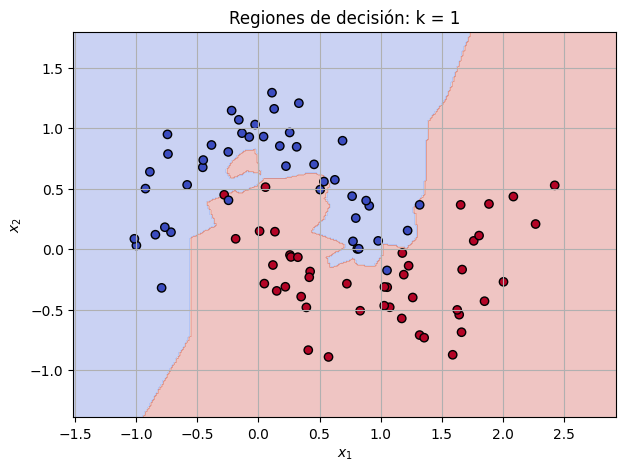

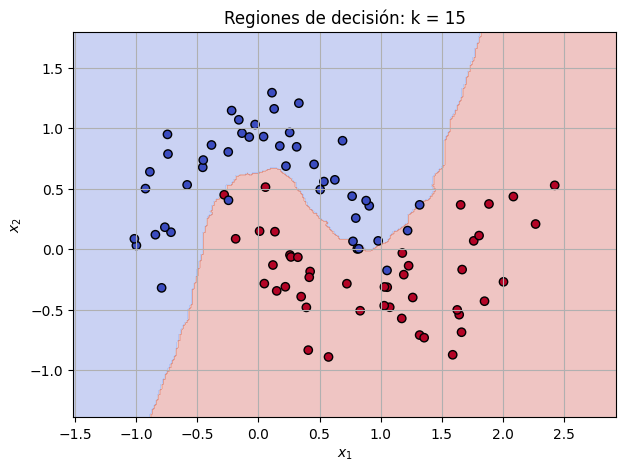

In [ ]:
def graficar_regiones(modelo, X, y, titulo):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    puntos_malla = np.c_[xx.ravel(), yy.ravel()]
    Z = modelo.predict(puntos_malla)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="black"
    )

    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.title(titulo)
    plt.grid(True)
    plt.show()


# Graficar k = 1 y k = 15
graficar_regiones(
    resultados[1],
    X_test,
    y_test,
    "Regiones de decisión: k = 1"
)

graficar_regiones(
    resultados[15],
    X_test,
    y_test,
    "Regiones de decisión: k = 15"
)

# Métricas de evaluación de clasificación

En esta sección se evalúa el desempeño de un clasificador binario comparando las etiquetas reales con las predicciones del modelo. Para tener un panorama completo del rendimiento más allá de la exactitud simple, se construye la **matriz de confusión**, identificando los Verdaderos Negativos ($TN$), Falsos Positivos ($FP$), Falsos Negativos ($FN$) y Verdaderos Positivos ($TP$).

A partir de estos valores se calculan e interpretan las siguientes métricas fundamentales utilizando **scikit-learn**:
- **Exactitud (Accuracy):** Proporción total de predicciones correctas.
- **Precisión (Precision):** Proporción de predicciones positivas que fueron realmente correctas.
- **Sensibilidad (Recall / Exhaustividad):** Proporción de casos positivos reales que el modelo logró identificar.
- **F1-Score:** Media armónica entre precisión y recall, ideal para conjuntos con cierto desbalance.

Para facilitar la interpretación, se incluye el reporte de clasificación completo y la visualización gráfica de la matriz de confusión.

In [ ]:
import numpy as np

y_real = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

matriz = confusion_matrix(
    y_real,
    y_pred,
    labels=[0, 1]
)

print("Matriz de confusión:")
print(matriz)

exactitud = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred, pos_label=1)
recall = recall_score(y_real, y_pred, pos_label=1)
f1 = f1_score(y_real, y_pred, pos_label=1)

print(f"\nExactitud (accuracy): {exactitud:.4f}")
print(f"Precisión (precision): {precision:.4f}")
print(f"Exhaustividad (recall): {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_real, y_pred, zero_division=0))

Matriz de confusión:
[[3 1]
 [2 4]]

Exactitud (accuracy): 0.7000
Precisión (precision): 0.8000
Exhaustividad (recall): 0.6667
F1-score: 0.7273

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.60      0.75      0.67         4
           1       0.80      0.67      0.73         6

    accuracy                           0.70        10
   macro avg       0.70      0.71      0.70        10
weighted avg       0.72      0.70      0.70        10



In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Clase 0", "Clase 1"]
)